# Phase 9 Validation & Analysis

Authoritative validation notebook for `data/processed/scores/complexity_index_v1.csv` (self-contained — re-derives team-size correlation and manual outlier review fresh rather than citing `notebooks/score_design.ipynb`). Covers score distribution, technical-vs-practical relationship, complexity by batch/status/industry, a full correlation heatmap, team-size correlation, targeted validation questions, manual outlier review, and findings, per `docs/superpowers/specs/2026-07-13-phase9-validation-analysis-design.md`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

scores_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "scores" / "complexity_index_v1.csv")
features_df = pd.read_parquet(REPO_ROOT / "data" / "processed" / "features" / "complexity_features.parquet")
companies_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "step3_enriched" / "companies_enriched.csv")
industries_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "step3_enriched" / "industries_enriched.csv")

merged = scores_df.merge(companies_df[["id", "teamSize"]], on="id", how="left")
merged["log_team_size"] = np.log1p(merged["teamSize"])

feature_cols = [c for c in features_df.columns if c not in ("id", "slug", "name", "batch", "status")]
merged = merged.merge(features_df[["id"] + feature_cols], on="id", how="left")

industry_merged = scores_df.merge(industries_df, on="id", how="left")

merged.shape, industry_merged.shape

((4844, 24), (8857, 15))

## 1. Score Distribution

Objectives doc target: standard deviation ≥ 15 points (avoid clustering).

array([[<Axes: title={'center': 'complexity_score'}>,
        <Axes: title={'center': 'technical_score'}>,
        <Axes: title={'center': 'practical_score'}>]], dtype=object)

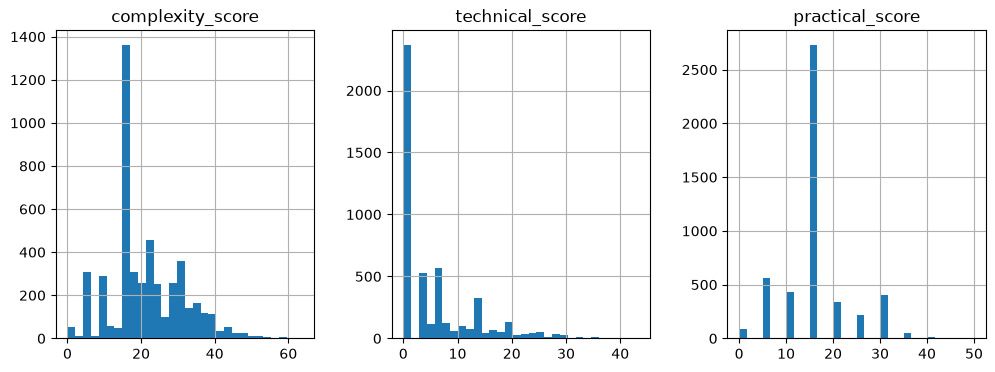

In [2]:
merged[["complexity_score", "technical_score", "practical_score"]].hist(bins=30, figsize=(12, 4), layout=(1, 3))

In [3]:
std = merged["complexity_score"].std()
print(f"complexity_score std: {std:.2f} (target: >= 15)")
merged["complexity_score"].describe()

complexity_score std: 10.11 (target: >= 15)


count    4844.000000
mean       21.029149
std        10.108302
min         0.000000
25%        15.000000
50%        18.800000
75%        28.300000
max        63.800000
Name: complexity_score, dtype: float64

## 2. Technical vs Practical

Checks whether the two 0-50 sub-scores move together or measure independent dimensions of complexity, as the rubric intends.

Correlation between technical_score and practical_score: -0.049


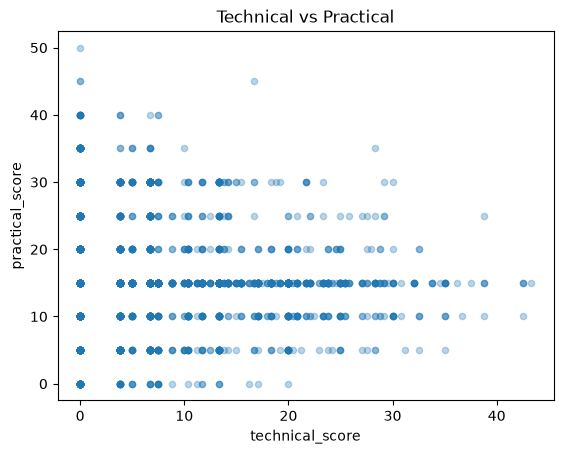

In [4]:
merged.plot(kind="scatter", x="technical_score", y="practical_score", alpha=0.3, title="Technical vs Practical")
tp_corr = merged["technical_score"].corr(merged["practical_score"])
print(f"Correlation between technical_score and practical_score: {tp_corr:.3f}")

## 3. Complexity by Batch

Mean/median `complexity_score` per batch, ordered chronologically (Winter before Summer within the same year), not alphabetically.

,batch,mean,median,count
0,S05,13.300000,15.0,8
20,W06,13.942857,15.0,7
1,S06,10.300000,8.8,11
21,W07,9.815385,10.0,13
2,S07,11.136842,8.8,19
22,W08,12.809524,15.0,21
3,S08,11.068182,6.9,22
23,W09,10.562500,9.4,16
4,S09,14.384615,15.0,26
24,W10,12.837037,15.0,27


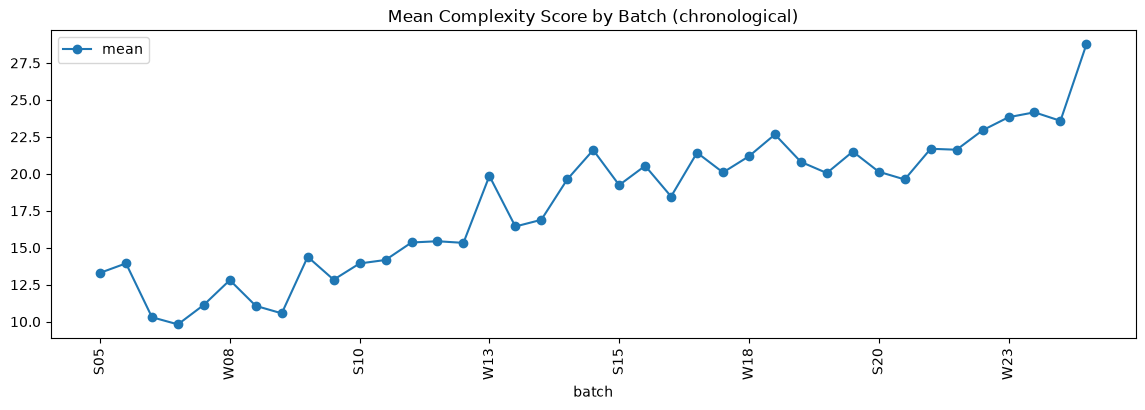

In [5]:
def batch_sort_key(batch: str) -> tuple:
    year = int(batch[1:])
    season_order = 0 if batch[0] == "W" else 1
    return (year, season_order)

batch_summary = merged.groupby("batch")["complexity_score"].agg(["mean", "median", "count"]).reset_index()
batch_summary["sort_key"] = batch_summary["batch"].apply(batch_sort_key)
batch_summary = batch_summary.sort_values("sort_key").drop(columns="sort_key")

batch_summary.plot(
    x="batch", y="mean", kind="line", marker="o", figsize=(14, 4),
    title="Mean Complexity Score by Batch (chronological)", rot=90,
)
batch_summary

## 4. Complexity by Status

Validation question: are Public companies more complex than average?

In [6]:
status_summary = merged.groupby("status")["complexity_score"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False)
overall_mean = merged["complexity_score"].mean()
print(f"Overall mean complexity_score: {overall_mean:.2f}")
status_summary

Overall mean complexity_score: 21.03


,mean,median,count
status,,,
Public,22.694737,21.7,19
Active,22.588637,21.7,3441
Acquired,17.691192,15.0,579
Inactive,16.724596,15.0,805


## 5. Complexity by Industry

Each company contributes its `complexity_score` to every industry it's tagged with (explode, not a single primary industry). Filtered to industries with >= 20 tagged companies to avoid noisy single-company averages.

,mean,count
industry,,
Drug Discovery and Delivery,39.350000,42
Legal,37.981818,33
Industrial Bio,35.020588,34
Medical Devices,34.002381,42
Finance and Accounting,33.982883,111
Therapeutics,33.739344,61
Manufacturing and Robotics,30.536508,63
Supply Chain and Logistics,30.313158,114
Diagnostics,30.307407,54


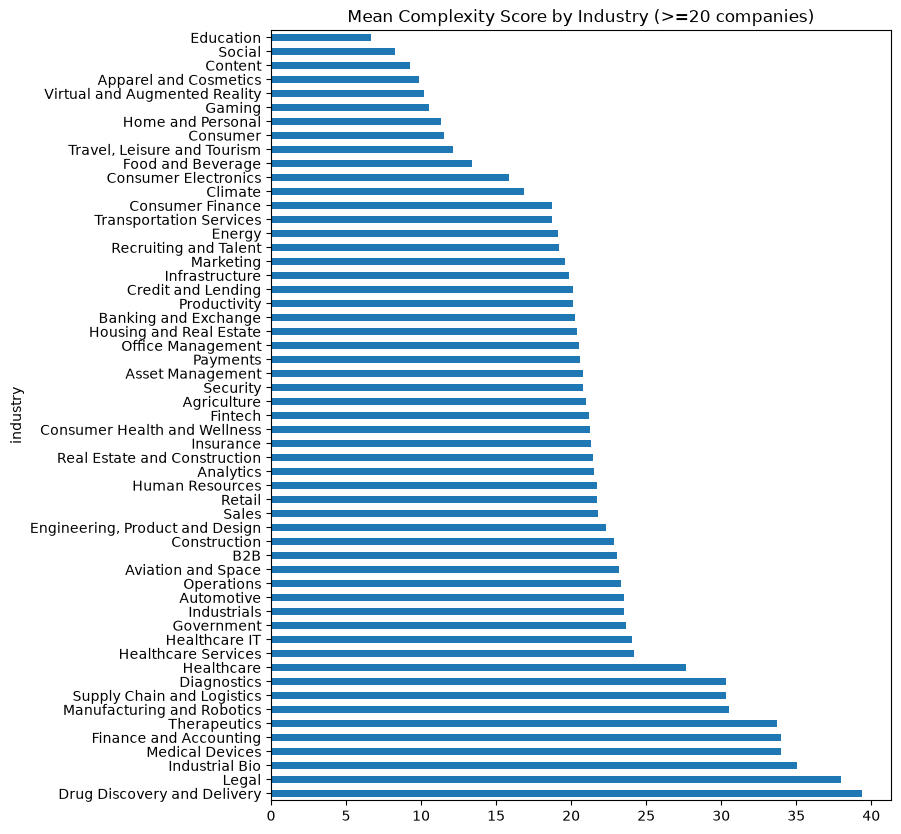

In [7]:
industry_summary = (
    industry_merged.groupby("industry")["complexity_score"]
    .agg(["mean", "count"])
    .query("count >= 20")
    .sort_values("mean", ascending=False)
)
industry_summary.plot(
    kind="barh", y="mean", figsize=(8, 10),
    title="Mean Complexity Score by Industry (>=20 companies)", legend=False,
)
industry_summary